# Initial exploration

HPD service requests from NYC 311, created between 1 Nov 2023 and 30 Oct 2026.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_parquet("../data/HPD_requests.parquet")
df.shape

(2386138, 6)

In [3]:
df.head()

,unique_key,created_date,agency,complaint_type,borough,open_data_channel_type
0,59291270,2023-11-01 14:21:31,HPD,APPLIANCE,BRONX,PHONE
1,59291271,2023-11-01 08:47:02,HPD,APPLIANCE,BRONX,PHONE
2,59291272,2023-11-01 14:14:56,HPD,APPLIANCE,MANHATTAN,PHONE
3,59291273,2023-11-01 13:59:44,HPD,APPLIANCE,BRONX,PHONE
4,59291274,2023-11-01 14:29:05,HPD,APPLIANCE,BRONX,PHONE


In [4]:
df.dtypes

unique_key                         int64
created_date              datetime64[us]
agency                          category
complaint_type                  category
borough                         category
open_data_channel_type          category
dtype: object

In [5]:
df.isna().sum()

unique_key                0
created_date              0
agency                    0
complaint_type            0
borough                   0
open_data_channel_type    0
dtype: int64

In [6]:
df["unique_key"].is_unique

True

In [7]:
df["created_date"].min(), df["created_date"].max()

(Timestamp('2023-11-01 00:01:39'), Timestamp('2026-10-30 23:54:14'))

In [8]:
df["open_data_channel_type"].value_counts(normalize=True).round(3)

open_data_channel_type
PHONE     0.474
ONLINE    0.455
MOBILE    0.070
Name: proportion, dtype: float64

In [9]:
df["borough"].value_counts()

borough
BRONX            825168
BROOKLYN         685730
MANHATTAN        527030
QUEENS           310270
STATEN ISLAND     37937
Unspecified           3
Name: count, dtype: int64

In [10]:
df["complaint_type"].value_counts()

complaint_type
HEAT/HOT WATER          904508
UNSANITARY CONDITION    378079
PLUMBING                219179
PAINT/PLASTER           193843
DOOR/WINDOW             145778
WATER LEAK              133632
GENERAL                 109455
ELECTRIC                 94435
FLOORING/STAIRS          85619
APPLIANCE                71717
SAFETY                   40909
ELEVATOR                  5490
OUTSIDE BUILDING          3493
Safety                       1
Name: count, dtype: int64

## Daily counts

In [11]:
daily = df.groupby(df["created_date"].dt.normalize()).size()
daily.describe()

count    1090.000000
mean     2189.117431
std      1124.848019
min       473.000000
25%      1520.000000
50%      1936.500000
75%      2671.500000
max      8228.000000
dtype: float64

In [12]:
all_days = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
all_days.difference(daily.index)

DatetimeIndex(['2024-04-11', '2024-04-12', '2024-04-13', '2024-04-14',
               '2024-07-13'],
              dtype='datetime64[us]', freq=None)

In [13]:
daily["2024-04-08":"2024-04-18"]

created_date
2024-04-08    1843
2024-04-09    1814
2024-04-10    1835
2024-04-15    7398
2024-04-16    1967
2024-04-17    1980
2024-04-18    2398
dtype: int64

No rows at all on those five days, and 15 Apr 2024 is one of the busiest days in the data, so this looks like a feed outage and then a backlog.

In [14]:
daily.nlargest(10)

created_date
2026-02-08    8228
2026-01-30    7852
2026-02-09    7402
2024-04-15    7398
2024-12-23    7181
2025-01-22    7127
2026-01-24    7098
2025-01-21    6944
2026-01-25    6844
2026-01-27    6548
dtype: int64

In [15]:
daily.nsmallest(10)

created_date
2025-07-04    473
2024-03-16    528
2025-03-16    601
2025-05-11    610
2024-07-28    622
2025-06-15    639
2024-03-17    642
2025-07-05    642
2024-06-16    649
2024-07-04    654
dtype: int64

In [16]:
by_weekday = daily.groupby(daily.index.day_of_week).mean().round()
by_weekday.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
by_weekday

Mon    2626.0
Tue    2574.0
Wed    2453.0
Thu    2348.0
Fri    2186.0
Sat    1539.0
Sun    1585.0
dtype: float64

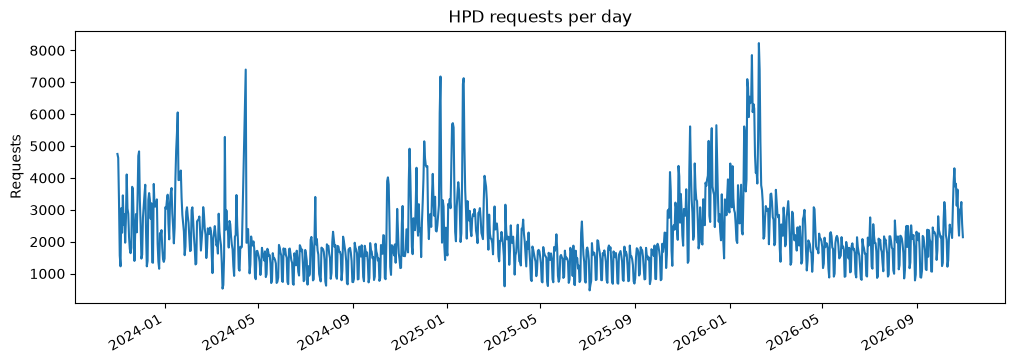

In [17]:
fig, ax = plt.subplots(figsize=(12, 4))
daily.plot(ax=ax)
ax.set_title("HPD requests per day")
ax.set_xlabel("")
ax.set_ylabel("Requests")
plt.show()

## Channels

In [18]:
monthly = pd.crosstab(df["created_date"].dt.to_period("M"), df["open_data_channel_type"])
monthly

open_data_channel_type,MOBILE,ONLINE,PHONE
created_date,,,
2023-11,8009,35919,42839
2023-12,6144,34686,34050
2024-01,9213,44344,45446
2024-02,5555,30030,30329
2024-03,4962,26810,31416
2024-04,3109,21787,27964
2024-05,1091,16017,25608
2024-06,647,12533,26821
2024-07,793,13862,30406
